# بيّن: متى يرتفع التبرع في منصة إحسان؟

**فريق بيّن** · مسابقة تحليل البيانات

**السؤال:** متى يرتفع عدد المتبرعين في اليوم؟ وهل يرتبط الارتفاع بالمواسم الدينية، أو بيوم الأسبوع، أو بمواعيد صرف الرواتب والمعاشات والدعم؟

**القرار الذي ندعمه:** ترشيح فترات لاختبار الحملات الإعلانية (لا تحديد «أفضل وقت للإعلان»، لأن البيانات لا تتضمن أي معلومات عن الإعلانات).

**طريقة التشغيل:** `Runtime → Restart session and run all`. في Colab تطلب الخلية الأولى رفع الملف النظيف؛ ومن جذر المستودع يُقرأ من `data_clean/` مباشرة. كل الجداول تُحفظ في `outputs/tables/` والرسوم في `outputs/figures/`.

## الخطوة 0: تحميل الملف النظيف
الملف ناتج دفتر التنظيف (الخلايا 1–8)، ونتحقق أنه النسخة النهائية قبل البدء.

In [1]:
# ============================================================
# STEP 0 - Load the cleaned file
#   In Colab: upload ehsan_rows_2021-04_2023-06.csv (from data_clean/ in the repo, or from the cleaning notebook).
#   Locally (from the repo root): the file is read from data_clean/ directly.
# ============================================================
from pathlib import Path

INPUT_CSV = Path("data_clean/ehsan_rows_2021-04_2023-06.csv")
OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not INPUT_CSV.exists():
    INPUT_CSV = Path("ehsan_rows_2021-04_2023-06.csv")
    uploaded = files.upload()
    csvs = [name for name in uploaded if name.lower().endswith(".csv")]
    assert csvs, "No CSV uploaded - please choose ehsan_rows_2021-04_2023-06.csv"
    if csvs[0] != INPUT_CSV.name:
        Path(csvs[0]).replace(INPUT_CSV)  # rename to the standard name used by STEP 1

with open(INPUT_CSV, encoding="utf-8-sig") as f:
    header = f.readline()
assert "Recurring_01" in header and "flag_dup_extra" in header, \
    "This is not the final cleaned file - run CELL 1-8 in the cleaning notebook and download it again"
print(f"Input: {INPUT_CSV} ({INPUT_CSV.stat().st_size / 1e6:.1f} MB) | outputs go to {OUT_DIR}/")


Input: data_clean/ehsan_rows_2021-04_2023-06.csv (15.0 MB) | outputs go to outputs/


## الخطوة 1: اختيار الأعمدة
نحتفظ بالأعمدة التي يحتاجها التحليل فقط، ونتحقق أن عدد الصفوف ومجموع المبالغ لم يتغيرا.

In [2]:
# STEP 1 - Load the cleaned file and keep only the columns the analysis needs
import pandas as pd

raw = pd.read_csv(INPUT_CSV, sep=";", encoding="utf-8-sig",
                  dtype={"UserID_clean": str}, parse_dates=["Gregorian_Date"])

ANALYSIS_COLS = ["RowID", "UserID_clean", "Gregorian_Date", "Hijri_Year", "Hijri_Month", "Hijri_Month_Name",
                 "Hijri_Day", "Hijri_Month_Complete", "InitiativeName_clean", "Amount_num"]
TEMP_COLS = ["Recurring_01", "flag_dup_extra", "dup_group", "dup_group_size"]  # used in steps 2-3, then dropped

df_analysis = raw[ANALYSIS_COLS + TEMP_COLS].copy()

assert len(df_analysis) == len(raw) and df_analysis["Amount_num"].sum() == raw["Amount_num"].sum()
assert df_analysis["RowID"].is_unique
print(f"Rows: {len(df_analysis)} | columns: {raw.shape[1]} -> {df_analysis.shape[1]}")
df_analysis.head()


Rows: 40548 | columns: 45 -> 14


,RowID,UserID_clean,Gregorian_Date,Hijri_Year,Hijri_Month,Hijri_Month_Name,Hijri_Day,Hijri_Month_Complete,InitiativeName_clean,Amount_num,Recurring_01,flag_dup_extra,dup_group,dup_group_size
0,R05771,U5C2,2021-04-01,1442,8,شعبان,19,False,مشروع,5,0,False,NaN,1
1,R14199,U9D9,2021-04-02,1442,8,شعبان,20,False,مشروع,10,0,False,NaN,1
2,R14187,U9D9,2021-04-02,1442,8,شعبان,20,False,مشروع,10,0,False,NaN,1
3,R14180,U9D9,2021-04-02,1442,8,شعبان,20,False,مشروع,10,0,False,NaN,1
4,R14259,U9D9,2021-04-02,1442,8,شعبان,20,False,مشروع,10,0,False,NaN,1


## الخطوة 2: استبعاد السحب التلقائي
التبرع الدوري يسحبه النظام في وقت يحدده هو، فلا يعكس قرار المتبرع. نحفظ المستبعد في جدول مستقل.

In [3]:
# STEP 2 - Remove automatic charges (Recurring_01 = 1): their time is set by the system, not the donor
before = df_analysis
is_auto = before["Recurring_01"] == 1

excluded_recurring = before[is_auto].copy()
df_analysis = before[~is_auto].drop(columns="Recurring_01").reset_index(drop=True)

assert len(df_analysis) + len(excluded_recurring) == len(before)
assert df_analysis["Amount_num"].sum() + excluded_recurring["Amount_num"].sum() == before["Amount_num"].sum()
print(f"Removed automatic charges: {len(excluded_recurring)} rows ({excluded_recurring['Amount_num'].sum():,} SAR)")
print(f"Kept: {len(df_analysis)} rows | donors: {df_analysis['UserID_clean'].nunique()}")


Removed automatic charges: 10981 rows (96,125 SAR)
Kept: 29567 rows | donors: 1362


## الخطوة 3: دمج النسخ المكررة
السجلات المتطابقة في المتبرع والمبلغ والمبادرة والوقت تُعدّ عملية واحدة.

In [4]:
# STEP 3 - Merge duplicate copies (flag_dup_extra): one transaction per group, first row kept
before = df_analysis
is_extra = before["flag_dup_extra"].astype(bool)

excluded_duplicates = before[is_extra].copy()
df_analysis = before[~is_extra].reset_index(drop=True)
df_analysis["Copies_merged"] = df_analysis["dup_group_size"].astype(int)  # 1 = no duplicate
df_analysis = df_analysis.drop(columns=["flag_dup_extra", "dup_group", "dup_group_size"])

assert len(df_analysis) + len(excluded_duplicates) == len(before)
assert df_analysis["Amount_num"].sum() + excluded_duplicates["Amount_num"].sum() == before["Amount_num"].sum()
assert df_analysis["Copies_merged"].sum() == len(before)
print(f"Merged duplicate copies: {len(excluded_duplicates)} rows ({excluded_duplicates['Amount_num'].sum():,} SAR)")
print(f"Kept: {len(df_analysis)} rows | donors: {df_analysis['UserID_clean'].nunique()} | columns: {df_analysis.shape[1]}")


Merged duplicate copies: 45 rows (4,569 SAR)
Kept: 29522 rows | donors: 1362 | columns: 11


## الخطوة 4: جدول متبرع-يوم
صف واحد لكل متبرع في كل يوم، لأن المقياس الأساسي هو **عدد المتبرعين المختلفين في اليوم**.

In [5]:
# STEP 4 - Donor-day table: one row per donor per day (all donations of the same donor on the same date combined)
CAL_COLS = ["Hijri_Year", "Hijri_Month", "Hijri_Month_Name", "Hijri_Day", "Hijri_Month_Complete"]

df_donor_day = (df_analysis
                .groupby(["UserID_clean", "Gregorian_Date"])
                .agg(Donations=("RowID", "size"), Amount=("Amount_num", "sum"),
                     Initiatives=("InitiativeName_clean", "nunique"), **{c: (c, "first") for c in CAL_COLS})
                .reset_index())

assert not df_donor_day.duplicated(["UserID_clean", "Gregorian_Date"]).any()
assert df_donor_day["Donations"].sum() == len(df_analysis)
assert df_donor_day["Amount"].sum() == df_analysis["Amount_num"].sum()
print(f"Donations: {len(df_analysis)} -> donor-days: {len(df_donor_day)} | donors: {df_donor_day['UserID_clean'].nunique()}")
df_donor_day.head()


Donations: 29522 -> donor-days: 17097 | donors: 1362


,UserID_clean,Gregorian_Date,Donations,Amount,Initiatives,Hijri_Year,Hijri_Month,Hijri_Month_Name,Hijri_Day,Hijri_Month_Complete
0,800U,2021-04-19,2,60,1,1442,9,رمضان,7,True
1,800U,2021-04-21,2,50,1,1442,9,رمضان,9,True
2,800U,2021-07-19,1,20,1,1442,12,ذو الحجة,9,True
3,800U,2022-04-11,2,70,2,1443,9,رمضان,10,True
4,8013,2021-05-07,1,21,1,1442,9,رمضان,25,True


## الخطوة 5: الجدول اليومي
صف لكل يوم ميلادي مع التاريخ الهجري (أم القرى). الأيام بلا بيانات تُترك فارغة ولا تُحسب صفراً.

In [6]:
# STEP 5 - Daily table: one row per calendar day (days without data stay EMPTY, not 0)
import subprocess, sys
try:
    from hijridate import Gregorian
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "hijridate"], check=True)
    from hijridate import Gregorian

days = pd.date_range(df_donor_day["Gregorian_Date"].min(), df_donor_day["Gregorian_Date"].max(), freq="D")
hijri = [Gregorian(d.year, d.month, d.day).to_hijri() for d in days]
df_daily = pd.DataFrame({"Gregorian_Date": days, "Weekday": days.day_name(),
                         "Hijri_Year": [h.year for h in hijri], "Hijri_Month": [h.month for h in hijri],
                         "Hijri_Month_Name": [h.month_name("ar") for h in hijri], "Hijri_Day": [h.day for h in hijri]})

totals = df_donor_day.groupby("Gregorian_Date").agg(Donors=("UserID_clean", "size"), Donations=("Donations", "sum"),
                                                    Amount=("Amount", "sum"))
df_daily = df_daily.merge(totals, left_on="Gregorian_Date", right_index=True, how="left")
df_daily["has_data"] = df_daily["Donors"].notna()

assert df_daily["Donors"].sum() == len(df_donor_day) and df_daily["Donations"].sum() == len(df_analysis)
assert df_daily["Amount"].sum() == df_analysis["Amount_num"].sum()
print(f"Days: {len(df_daily)} | with data: {df_daily['has_data'].sum()} | without data: {(~df_daily['has_data']).sum()}")
print(f"Donors per day: mean {df_daily['Donors'].mean():.1f}, median {df_daily['Donors'].median():.0f}")
df_daily.head()


Days: 821 | with data: 811 | without data: 10
Donors per day: mean 21.1, median 16


,Gregorian_Date,Weekday,Hijri_Year,Hijri_Month,Hijri_Month_Name,Hijri_Day,Donors,Donations,Amount,has_data
0,2021-04-01,Thursday,1442,8,شعبان,19,1.0,1.0,5.0,True
1,2021-04-02,Friday,1442,8,شعبان,20,1.0,5.0,60.0,True
2,2021-04-03,Saturday,1442,8,شعبان,21,2.0,2.0,150.0,True
3,2021-04-04,Sunday,1442,8,شعبان,22,1.0,3.0,1100.0,True
4,2021-04-05,Monday,1442,8,شعبان,23,NaN,NaN,NaN,False


## الخطوة 6: تقويم الصرف
القواعد الأساسية (الرواتب 27، التقاعد 25، حساب المواطن 10، برامج أول الشهر 1) مع ترحيلها عند الجمعة والسبت، ويُقدَّم عليها أي إعلان رسمي. نافذة الصرف = يوم الصرف + 3 أيام، وحُددت قبل رؤية النتائج.

In [7]:
# STEP 6 - Payday calendar (baseline rules; an official announcement for a specific month overrides the rule)
WEEKEND_SHIFT = {  # program -> (day of month, shift if Friday, shift if Saturday)
    "salary_27": (27, -1, +1),        # state employees: Fri -> 26, Sat -> 28
    "pension_25": (25, -1, +1),       # civil & military retirement: Fri -> 24, Sat -> 26
    "citizen_10": (10, -1, +1),       # Citizen Account: Fri -> 9, Sat -> 11
    "day1_group": (1, -1, -2),        # GOSI pensions + Saned + social security (from Jun 2022): Fri/Sat -> Thursday (to verify)
}
OVERRIDES = {  # (program, "YYYY-MM") -> (announced date, source)
    ("citizen_10", "2022-07"): ("2022-07-06", "Citizen Account spokesperson via Al-Marsd (payment 56)"),
}
PROGRAM_LABEL = {"salary_27": "State salaries (27th)", "pension_25": "Civil/military pensions (25th)",
                 "citizen_10": "Citizen Account (10th)",
                 "day1_group": "Day-1 payments (GOSI pensions, Saned, social security)"}

rows = []
for month in pd.date_range("2021-03-01", "2023-07-01", freq="MS"):  # one month of margin on each side
    for prog, (dom, fri, sat) in WEEKEND_SHIFT.items():
        rule = month + pd.Timedelta(days=dom - 1)
        shift = {4: fri, 5: sat}.get(rule.dayofweek, 0)  # 4 = Friday, 5 = Saturday
        pay, status, source = rule + pd.Timedelta(days=shift), "rule", "baseline rule"
        if prog == "day1_group" and shift:
            status = "check (weekend shift from secondary sources)"
        key = (prog, month.strftime("%Y-%m"))
        if key in OVERRIDES:
            pay, status, source = pd.Timestamp(OVERRIDES[key][0]), "announced", OVERRIDES[key][1]
        rows.append({"Program": prog, "Month": key[1], "Pay_Date": pay, "Weekday": pay.day_name(),
                     "Status": status, "Source": source})
payday_calendar = pd.DataFrame(rows)

# Flags on the daily table: payday, days since the last payday, and the main window (payday + 3 days)
WINDOW_DAYS = 3  # fixed before looking at the results
for prog in WEEKEND_SHIFT:
    pays = payday_calendar.loc[payday_calendar["Program"] == prog, ["Pay_Date"]].sort_values("Pay_Date")
    since = pd.merge_asof(df_daily[["Gregorian_Date"]], pays, left_on="Gregorian_Date", right_on="Pay_Date",
                          direction="backward")["Pay_Date"]
    df_daily[f"{prog}_days_since"] = (df_daily["Gregorian_Date"] - since).dt.days.to_numpy()
    df_daily[f"{prog}_window"] = df_daily[f"{prog}_days_since"].between(0, WINDOW_DAYS).astype(int)

assert not payday_calendar.duplicated(["Program", "Month"]).any()
assert (payday_calendar.query("Status != 'announced'")["Pay_Date"].dt.dayofweek.isin([4, 5])).sum() == 0
print("Paydays per program inside the period:")
print(payday_calendar[payday_calendar["Pay_Date"].between(df_daily["Gregorian_Date"].min(), df_daily["Gregorian_Date"].max())]
      .groupby(["Program", "Status"]).size().to_string())
print("Not covered: social security before June 2022 (no reliable historical dates found - no date assumed)")
payday_calendar.head(8)


Paydays per program inside the period:
Program     Status                                      
citizen_10  announced                                        1
            rule                                            26
day1_group  check (weekend shift from secondary sources)     8
            rule                                            20
pension_25  rule                                            27
salary_27   rule                                            27
Not covered: social security before June 2022 (no reliable historical dates found - no date assumed)


,Program,Month,Pay_Date,Weekday,Status,Source
0,salary_27,2021-03,2021-03-28,Sunday,rule,baseline rule
1,pension_25,2021-03,2021-03-25,Thursday,rule,baseline rule
2,citizen_10,2021-03,2021-03-10,Wednesday,rule,baseline rule
3,day1_group,2021-03,2021-03-01,Monday,rule,baseline rule
4,salary_27,2021-04,2021-04-27,Tuesday,rule,baseline rule
5,pension_25,2021-04,2021-04-25,Sunday,rule,baseline rule
6,citizen_10,2021-04,2021-04-11,Sunday,rule,baseline rule
7,day1_group,2021-04,2021-04-01,Thursday,rule,baseline rule


## تحليل 1: هل يرتفع التبرع بعد أيام الصرف؟
نموذج بواسون يضبط يوم الأسبوع ونمو العينة والمواسم، مع أخطاء HAC. وفحص ثانٍ: «عرض الحدث» حول كل يوم صرف. لا نحكم بـ«ارتفاع واضح» إلا إذا اتفقت الطريقتان.

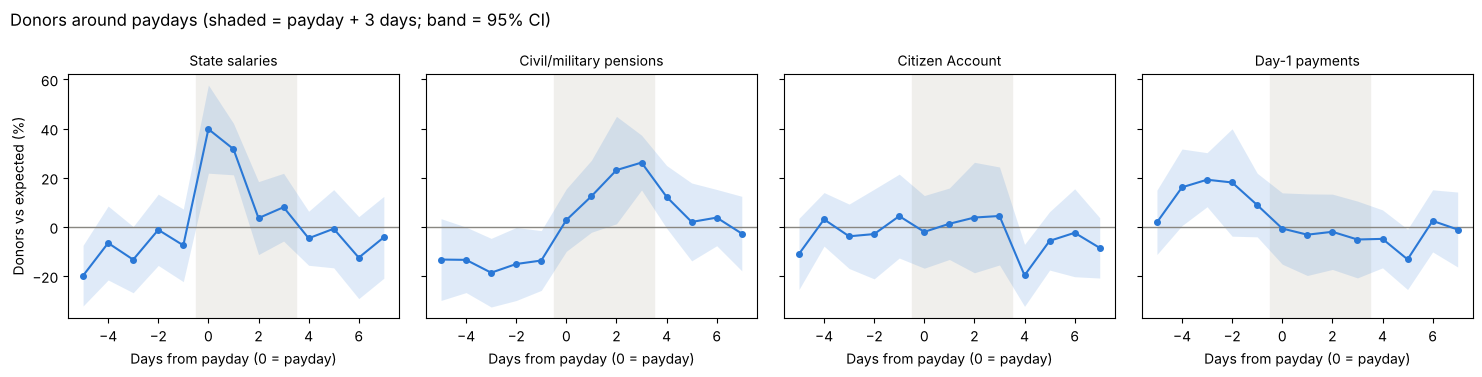

Days used: 811 (days without data excluded)


,Payment,Window_days,Overlap_with_salary_window_%,Change_%,CI_low_%,CI_high_%,p_value,Paydays,Event_view_%,Event_CI_low_%,Conclusion
0,State salaries (27th),108,100,25.6,11.7,41.2,0.0001,27,20.8,10.7,Clear rise
1,Civil/military pensions (25th),108,51,17.8,7.8,28.7,0.0003,27,16.1,6.0,"Rise, but mostly the salary days (overlap)"
2,Citizen Account (10th),107,0,12.6,1.3,25.2,0.0278,27,1.2,-13.9,Not confirmed by the event view
3,"Day-1 payments (GOSI pensions, Saned, social s...",109,14,8.4,-1.3,19.2,0.0930,28,-3.6,-15.8,No clear rise


In [8]:
# ANALYSIS - Do donors rise after paydays?
#   Compare days in each payday window (payday + 3 days) with comparable days outside it, controlling for
#   day of week, sample growth (smooth trend) and religious seasons. Poisson model, HAC errors (days are not independent).
#   Association in this sample, not proof of cause, and not proof that donors are employees or retirees.
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

m, dh = df_daily["Hijri_Month"], df_daily["Hijri_Day"]
df_daily["ramadan_1_20"] = ((m == 9) & (dh <= 20)).astype(int)
df_daily["ramadan_last10"] = ((m == 9) & (dh >= 21)).astype(int)
df_daily["eid_fitr"] = ((m == 10) & (dh <= 3)).astype(int)
df_daily["dhul_hijjah_1_9"] = ((m == 12) & (dh <= 9)).astype(int)
df_daily["eid_adha"] = ((m == 12) & dh.between(10, 13)).astype(int)
SEASON_CONTROLS = ["ramadan_1_20", "ramadan_last10", "eid_fitr", "dhul_hijjah_1_9", "eid_adha"]
WINDOWS = [f"{p}_window" for p in WEEKEND_SHIFT]

data = df_daily[df_daily["has_data"]].copy()
data["Donors"] = data["Donors"].astype(int)
data["t"] = (data["Gregorian_Date"] - data["Gregorian_Date"].min()).dt.days
base_terms = "C(Weekday, Treatment('Sunday')) + cr(t, df=4, constraints='center') + " + " + ".join(SEASON_CONTROLS)
model = smf.glm(f"Donors ~ {base_terms} + " + " + ".join(WINDOWS), data,
                family=sm.families.Poisson()).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
ci = model.conf_int()

# Event view: donors vs expected (model WITHOUT payday windows) around each payday
base = smf.glm(f"Donors ~ {base_terms}", data, family=sm.families.Poisson()).fit()
ratio = (data["Donors"] / base.fittedvalues).set_axis(data["Gregorian_Date"])
event_rows = []
for prog in WEEKEND_SHIFT:
    for p in payday_calendar.loc[payday_calendar["Program"] == prog, "Pay_Date"]:
        for k in range(-5, 8):
            event_rows.append({"Program": prog, "Payday": p, "day": k, "ratio": ratio.get(p + pd.Timedelta(days=k))})
events = pd.DataFrame(event_rows).dropna()
per_payday = events[events["day"].between(0, WINDOW_DAYS)].groupby(["Program", "Payday"])["ratio"].mean()
ev = per_payday.groupby("Program").agg(["mean", "sem", "size"])  # one value per payday -> CI across paydays

payday_results = pd.DataFrame([{
    "Payment": PROGRAM_LABEL[w.replace("_window", "")],
    "Window_days": int(data[w].sum()),
    "Overlap_with_salary_window_%": round(data.loc[data[w] == 1, "salary_27_window"].mean() * 100),
    "Change_%": round((np.exp(model.params[w]) - 1) * 100, 1),
    "CI_low_%": round((np.exp(ci.loc[w, 0]) - 1) * 100, 1),
    "CI_high_%": round((np.exp(ci.loc[w, 1]) - 1) * 100, 1),
    "p_value": round(model.pvalues[w], 4),
    "Paydays": int(ev.loc[w.replace("_window", ""), "size"]),
    "Event_view_%": round((ev.loc[w.replace("_window", ""), "mean"] - 1) * 100, 1),
    "Event_CI_low_%": round((ev.loc[w.replace("_window", ""), "mean"] - 1.96 * ev.loc[w.replace("_window", ""), "sem"] - 1) * 100, 1),
} for w in WINDOWS])
# "Clear rise" only when BOTH methods agree; a window that overlaps the salary window by 40%+ cannot be separated from it
both = (payday_results["CI_low_%"] > 0) & (payday_results["Event_CI_low_%"] > 0)
mixed = (payday_results["Overlap_with_salary_window_%"] >= 40) & (payday_results["Payment"] != PROGRAM_LABEL["salary_27"])
payday_results["Conclusion"] = np.select(
    [both & ~mixed, both & mixed, payday_results["CI_low_%"] > 0],
    ["Clear rise", "Rise, but mostly the salary days (overlap)", "Not confirmed by the event view"],
    "No clear rise")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, prog in zip(axes, WEEKEND_SHIFT):
    s = events[events["Program"] == prog].groupby("day")["ratio"].agg(["mean", "sem"])
    ax.axvspan(-0.5, WINDOW_DAYS + 0.5, color="#f0efec")
    ax.axhline(0, color="#898781", linewidth=1)
    ax.fill_between(s.index, (s["mean"] - 1.96 * s["sem"] - 1) * 100, (s["mean"] + 1.96 * s["sem"] - 1) * 100,
                    color="#2a78d6", alpha=0.15, linewidth=0)
    ax.plot(s.index, (s["mean"] - 1) * 100, color="#2a78d6", marker="o", markersize=4)
    ax.set_title(PROGRAM_LABEL[prog].split(" (")[0], fontsize=10)
    ax.set_xlabel("Days from payday (0 = payday)")
axes[0].set_ylabel("Donors vs expected (%)")
fig.suptitle("Donors around paydays (shaded = payday + 3 days; band = 95% CI)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "analysis_paydays.png", dpi=150)
plt.show()

assert int(model.nobs) == len(data)
print(f"Days used: {len(data)} (days without data excluded)")
payday_results


## تحليل 2: المواسم ويوم الجمعة
نموذج واحد يضبط كل العوامل معاً. الفحص الثاني للمواسم: مقارنة بآخر 28 يوماً عادياً قبل كل موسم؛ وللجمعة: مقارنتها بباقي أيام أسبوعها.

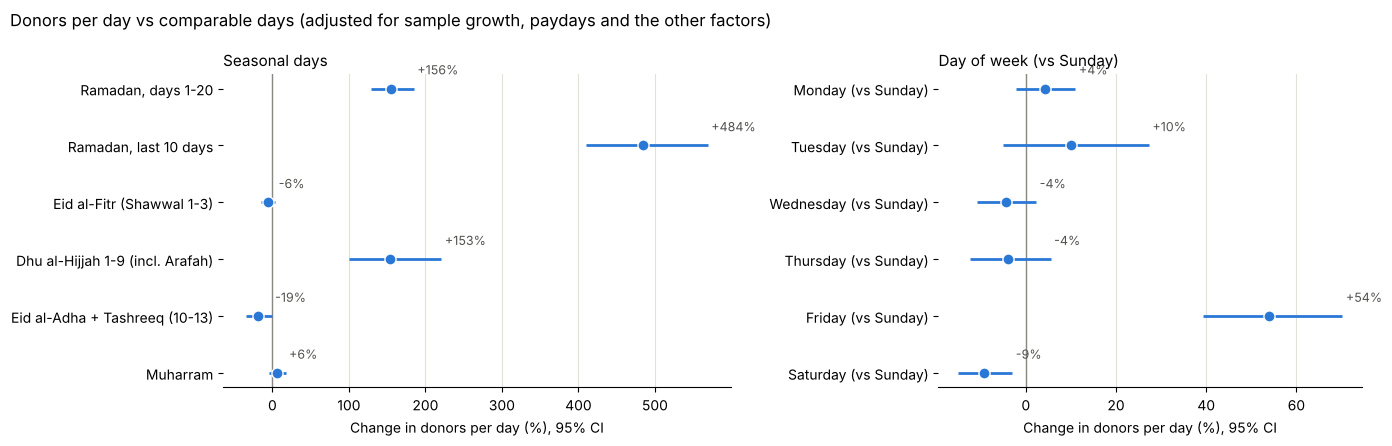

Days used: 811 | Friday above the average of the other 6 days in 96 of 109 full weeks


,Factor,Days,Change_%,CI_low_%,CI_high_%,p_value,Conclusion,Higher_than_ordinary_days_before
0,"Ramadan, days 1-20",60,155.6,129.4,184.9,0.0000,Clear rise,2 of 2
1,"Ramadan, last 10 days",29,484.0,409.7,569.1,0.0000,Clear rise,2 of 2
2,Eid al-Fitr (Shawwal 1-3),9,-5.7,-14.3,3.7,0.2231,No clear difference,1 of 2
3,Dhu al-Hijjah 1-9 (incl. Arafah),27,153.1,99.5,221.0,0.0000,Clear rise,3 of 3
4,Eid al-Adha + Tashreeq (10-13),11,-19.4,-34.3,-1.0,0.0397,Not consistent (model and check disagree),2 of 3
5,Muharram,59,5.6,-4.8,17.2,0.2998,No clear difference,2 of 2


,Factor,Days,Change_%,CI_low_%,CI_high_%,p_value,Conclusion
0,Monday (vs Sunday),116,4.2,-2.2,11.0,0.2051,No clear difference
1,Tuesday (vs Sunday),114,10.0,-5.0,27.3,0.2027,No clear difference
2,Wednesday (vs Sunday),115,-4.5,-10.8,2.3,0.1936,No clear difference
3,Thursday (vs Sunday),116,-3.9,-12.4,5.5,0.4032,No clear difference
4,Friday (vs Sunday),118,53.9,39.3,70.2,0.0000,Clear rise
5,Saturday (vs Sunday),117,-9.3,-15.1,-3.0,0.0044,Clear drop


In [9]:
# ANALYSIS - Ramadan, seasonal days and Friday: do donors rise?
#   One Poisson model of daily donors with: seasons + day of week + payday windows (STEP 6) + smooth trend (sample growth).
#   HAC errors (days are not independent). Plus a simple second check for each result.
#   Association in this sample, not proof of cause. Days split at midnight as recorded.
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

assert "salary_27_window" in df_daily.columns, "Run STEP 6 (payday calendar) first"

SEASONS = {
    "s_ramadan_1_20": ("Ramadan, days 1-20", lambda m, d: (m == 9) & (d <= 20)),
    "s_ramadan_last10": ("Ramadan, last 10 days", lambda m, d: (m == 9) & (d >= 21)),
    "s_eid_fitr": ("Eid al-Fitr (Shawwal 1-3)", lambda m, d: (m == 10) & (d <= 3)),
    "s_dhul_hijjah_1_9": ("Dhu al-Hijjah 1-9 (incl. Arafah)", lambda m, d: (m == 12) & (d <= 9)),
    "s_eid_adha": ("Eid al-Adha + Tashreeq (10-13)", lambda m, d: (m == 12) & d.between(10, 13)),
    "s_muharram": ("Muharram", lambda m, d: m == 1),
}
for col, (_, rule) in SEASONS.items():
    df_daily[col] = rule(df_daily["Hijri_Month"], df_daily["Hijri_Day"]).astype(int)
df_daily["any_season"] = df_daily[list(SEASONS)].max(axis=1)

data = df_daily[df_daily["has_data"]].copy()
data["Donors"] = data["Donors"].astype(int)
data["t"] = (data["Gregorian_Date"] - data["Gregorian_Date"].min()).dt.days
WINDOWS = [c for c in df_daily.columns if c.endswith("_window")]
formula = ("Donors ~ C(Weekday, Treatment('Sunday')) + cr(t, df=4, constraints='center') + "
           + " + ".join(list(SEASONS) + WINDOWS))
model = smf.glm(formula, data, family=sm.families.Poisson()).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
ci = model.conf_int()


def effect(term, label, days):
    return {"Factor": label, "Days": days, "Change_%": round((np.exp(model.params[term]) - 1) * 100, 1),
            "CI_low_%": round((np.exp(ci.loc[term, 0]) - 1) * 100, 1),
            "CI_high_%": round((np.exp(ci.loc[term, 1]) - 1) * 100, 1), "p_value": round(model.pvalues[term], 4)}


def conclude(t):
    t["Conclusion"] = np.select([t["CI_low_%"] > 0, t["CI_high_%"] < 0],
                                ["Clear rise", "Clear drop"], "No clear difference")
    return t


# ---------- Seasons: model + check vs the last 28 ordinary days before each occurrence ----------
season_results = conclude(pd.DataFrame([effect(c, lab, int(data[c].sum())) for c, (lab, _) in SEASONS.items()]))
checks = []
for col, (label, _) in SEASONS.items():
    on = data[data[col] == 1]
    for _, occ in on.groupby((on["Gregorian_Date"].diff().dt.days != 1).cumsum()):
        start = occ["Gregorian_Date"].min()
        before = data[(data["Gregorian_Date"] < start) & (data["Gregorian_Date"] >= start - pd.Timedelta(days=90))
                      & (data["any_season"] == 0)].tail(28)
        if len(before) >= 14:  # enough ordinary days before to compare
            checks.append({"Factor": label, "higher": occ["Donors"].mean() > before["Donors"].mean()})
chk = pd.DataFrame(checks).groupby("Factor")["higher"].agg(["sum", "size"])
season_results["Higher_than_ordinary_days_before"] = season_results["Factor"].map(
    lambda f: f"{int(chk.loc[f, 'sum'])} of {int(chk.loc[f, 'size'])}")
# Final conclusion only when the model and the check point the same way
share_up = season_results["Factor"].map(chk["sum"] / chk["size"])
agree = np.where(season_results["Conclusion"] == "Clear rise", share_up > 0.5,
                 np.where(season_results["Conclusion"] == "Clear drop", share_up < 0.5, True))
season_results.loc[~agree, "Conclusion"] = "Not consistent (model and check disagree)"

# ---------- Day of week: model (vs Sunday) + check: in how many weeks was Friday above the rest of its week ----------
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
weekday_results = conclude(pd.DataFrame(
    [effect(f"C(Weekday, Treatment('Sunday'))[T.{w}]", f"{w} (vs Sunday)", int((data["Weekday"] == w).sum()))
     for w in WEEKDAYS]))
wk = data.assign(week=data["Gregorian_Date"].dt.to_period("W-SAT"))  # weeks Sunday..Saturday
full = wk.groupby("week").filter(lambda g: len(g) == 7)
fri = full[full["Weekday"] == "Friday"].set_index("week")["Donors"]
rest = full[full["Weekday"] != "Friday"].groupby("week")["Donors"].mean()
friday_weeks = f"Friday above the average of the other 6 days in {int((fri > rest).sum())} of {len(fri)} full weeks"

# ---------- Chart ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
for ax, t, title in [(axes[0], season_results, "Seasonal days"), (axes[1], weekday_results, "Day of week (vs Sunday)")]:
    r = t.iloc[::-1].reset_index(drop=True)
    ax.axvline(0, color="#898781", linewidth=1)
    ax.hlines(r.index, r["CI_low_%"], r["CI_high_%"], color="#2a78d6", linewidth=2)
    ax.plot(r["Change_%"], r.index, "o", color="#2a78d6", markersize=8, markeredgecolor="white")
    for i, row in r.iterrows():
        ax.text(row["CI_high_%"], i + 0.25, f" {row['Change_%']:+.0f}%", fontsize=9, color="#52514e")
    ax.set_yticks(r.index, r["Factor"])
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Change in donors per day (%), 95% CI")
    ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
fig.suptitle("Donors per day vs comparable days (adjusted for sample growth, paydays and the other factors)",
             x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "analysis_seasons_friday.png", dpi=150)
plt.show()

assert int(model.nobs) == len(data) and (data[list(SEASONS)].sum(axis=1) <= 1).all()
print(f"Days used: {len(data)} | {friday_weeks}")
display(season_results)
display(weekday_results)


## النتيجة: الفترات المرشّحة
تُبنى آلياً من التحليلين أعلاه (لا تُكتب يدوياً)، مرتبة حسب حجم الارتفاع.

In [10]:
# RESULT - Candidate periods for testing campaigns (built from the two analyses above, not typed by hand)
#   Candidate = "Clear rise" in its analysis. Ranked by the size of the rise.
#   This ranks periods to TEST campaigns in; it does not prove the best time to advertise (no campaign data).
assert "payday_results" in globals() and "season_results" in globals(), \
    "Run the payday analysis and the seasons/Friday analysis first"

all_results = pd.concat([
    season_results.assign(Type="Season"),
    weekday_results.assign(Type="Day of week"),
    payday_results.rename(columns={"Payment": "Factor"}).assign(Type="Payday (payday + 3 days)"),
], ignore_index=True)[["Type", "Factor", "Change_%", "CI_low_%", "CI_high_%", "Conclusion"]]

candidates = (all_results[all_results["Conclusion"] == "Clear rise"]
              .sort_values("Change_%", ascending=False).reset_index(drop=True))
candidates.insert(0, "Rank", range(1, len(candidates) + 1))
not_supported = all_results[all_results["Conclusion"] != "Clear rise"].reset_index(drop=True)

assert len(candidates) + len(not_supported) == len(all_results)
print(f"Candidate periods (clear rise): {len(candidates)} | no clear evidence: {len(not_supported)}")
display(candidates)
display(not_supported)


Candidate periods (clear rise): 5 | no clear evidence: 11


,Rank,Type,Factor,Change_%,CI_low_%,CI_high_%,Conclusion
0,1,Season,"Ramadan, last 10 days",484.0,409.7,569.1,Clear rise
1,2,Season,"Ramadan, days 1-20",155.6,129.4,184.9,Clear rise
2,3,Season,Dhu al-Hijjah 1-9 (incl. Arafah),153.1,99.5,221.0,Clear rise
3,4,Day of week,Friday (vs Sunday),53.9,39.3,70.2,Clear rise
4,5,Payday (payday + 3 days),State salaries (27th),25.6,11.7,41.2,Clear rise


,Type,Factor,Change_%,CI_low_%,CI_high_%,Conclusion
0,Season,Eid al-Fitr (Shawwal 1-3),-5.7,-14.3,3.7,No clear difference
1,Season,Eid al-Adha + Tashreeq (10-13),-19.4,-34.3,-1.0,Not consistent (model and check disagree)
2,Season,Muharram,5.6,-4.8,17.2,No clear difference
3,Day of week,Monday (vs Sunday),4.2,-2.2,11.0,No clear difference
4,Day of week,Tuesday (vs Sunday),10.0,-5.0,27.3,No clear difference
5,Day of week,Wednesday (vs Sunday),-4.5,-10.8,2.3,No clear difference
6,Day of week,Thursday (vs Sunday),-3.9,-12.4,5.5,No clear difference
7,Day of week,Saturday (vs Sunday),-9.3,-15.1,-3.0,Clear drop
8,Payday (payday + 3 days),Civil/military pensions (25th),17.8,7.8,28.7,"Rise, but mostly the salary days (overlap)"
9,Payday (payday + 3 days),Citizen Account (10th),12.6,1.3,25.2,Not confirmed by the event view


## اختبار الثبات
نعيد النموذج 9 مرات ونغيّر في كل مرة اختياراً واحداً: المقياس (3)، ونافذة الراتب (3)، ومرونة الاتجاه الزمني (2)، وبداية الفترة (1). تبقى الفترة مرشّحة فقط إذا بقي ارتفاعها واضحاً في كل المرات.

In [11]:
# ROBUSTNESS - Re-run the main model 9 times, changing ONE choice each time
#   A period stays a candidate only if its rise is clear (CI fully above 0) in every variant.
assert "season_results" in globals() and "candidates" in globals(), "Run the analysis cells above first"

CANDIDATE_TERMS = {
    "Ramadan, last 10 days": "s_ramadan_last10",
    "Ramadan, days 1-20": "s_ramadan_1_20",
    "Dhu al-Hijjah 1-9 (incl. Arafah)": "s_dhul_hijjah_1_9",
    "Friday (vs Sunday)": "C(Weekday, Treatment('Sunday'))[T.Friday]",
    "State salaries (27th)": "salary_27_window",
}

# Alternative outcomes (built from the same tables as the main analysis)
cap = df_donor_day["Amount"].quantile(0.99)
amount_capped = df_donor_day.assign(A=df_donor_day["Amount"].clip(upper=cap)).groupby("Gregorian_Date")["A"].sum()
with_dups = pd.concat([df_analysis[["Gregorian_Date"]], excluded_duplicates[["Gregorian_Date"]]]).groupby("Gregorian_Date").size()


def windows_for(days_after):
    out = pd.DataFrame(index=df_daily.index)
    for prog in WEEKEND_SHIFT:
        out[f"{prog}_window"] = df_daily[f"{prog}_days_since"].between(0, days_after).astype(int)
    return out


def fit_variant(outcome="Donors", window_days=WINDOW_DAYS, trend_df=4, start=None):
    d = df_daily.drop(columns=[c for c in df_daily.columns if c.endswith("_window")]).join(windows_for(window_days))
    d = d[d["has_data"]].copy()
    if outcome == "Donations":
        d["y"] = d["Donations"]
    elif outcome == "Amount_capped":
        d["y"] = d["Gregorian_Date"].map(amount_capped)
    elif outcome == "Donations_with_dups":
        d["y"] = d["Gregorian_Date"].map(with_dups)
    else:
        d["y"] = d["Donors"]
    if start:
        d = d[d["Gregorian_Date"] >= start]
    d["y"] = d["y"].round().astype(int)
    d["t"] = (d["Gregorian_Date"] - d["Gregorian_Date"].min()).dt.days
    wins = [c for c in d.columns if c.endswith("_window")]
    f = (f"y ~ C(Weekday, Treatment('Sunday')) + cr(t, df={trend_df}, constraints='center') + "
         + " + ".join(list(SEASONS) + wins))
    m = smf.glm(f, d, family=sm.families.Poisson()).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    ci = m.conf_int()
    return {lab: ((np.exp(m.params[t]) - 1) * 100, (np.exp(ci.loc[t, 0]) - 1) * 100) for lab, t in CANDIDATE_TERMS.items()}


VARIANTS = {
    "Outcome: donations (not donors)": dict(outcome="Donations"),
    "Outcome: amount, capped at p99": dict(outcome="Amount_capped"),
    "Outcome: donations without merging duplicates": dict(outcome="Donations_with_dups"),
    "Payday window: payday only": dict(window_days=0),
    "Payday window: payday + 1 day": dict(window_days=1),
    "Payday window: payday + 5 days": dict(window_days=5),
    "Trend: less flexible (df=2)": dict(trend_df=2),
    "Trend: more flexible (df=8)": dict(trend_df=8),
    "Start in January 2022": dict(start="2022-01-01"),
}
rob_rows = []
for vname, kw in VARIANTS.items():
    for lab, (chg, lo) in fit_variant(**kw).items():
        rob_rows.append({"Variant": vname, "Factor": lab, "Change_%": round(chg, 1), "CI_low_%": round(lo, 1), "Clear_rise": lo > 0})
robustness = pd.DataFrame(rob_rows)

robustness_summary = (robustness.groupby("Factor", sort=False)
                      .agg(Min_change_pct=("Change_%", "min"), Max_change_pct=("Change_%", "max"),
                           Survived=("Clear_rise", "sum"), Variants=("Clear_rise", "size"))
                      .reset_index())
robustness_summary.insert(1, "Main_change_pct", robustness_summary["Factor"].map(candidates.set_index("Factor")["Change_%"]))
robustness_summary["Survived"] = robustness_summary["Survived"].astype(int).astype(str) + " of " + robustness_summary["Variants"].astype(str)
robustness_summary = robustness_summary.drop(columns="Variants")

assert len(robustness) == len(VARIANTS) * len(CANDIDATE_TERMS)
print(robustness_summary.to_string(index=False))


                          Factor  Main_change_pct  Min_change_pct  Max_change_pct Survived
           Ramadan, last 10 days            484.0           453.2           881.4   9 of 9
              Ramadan, days 1-20            155.6           147.4           219.7   9 of 9
Dhu al-Hijjah 1-9 (incl. Arafah)            153.1           135.5           394.9   9 of 9
              Friday (vs Sunday)             53.9            50.8            70.6   9 of 9
           State salaries (27th)             25.6            21.3            66.4   9 of 9


## نموذج التوقع
يتوقع عدد المتبرعين حتى 28 يوماً مقدماً من التقويم والمستوى المعتاد قبل شهر. نختبره على يناير–يونيو 2023 في كتل من 28 يوماً، وكل توقع يستخدم البيانات السابقة له فقط، ونقارنه بطريقتين بسيطتين.

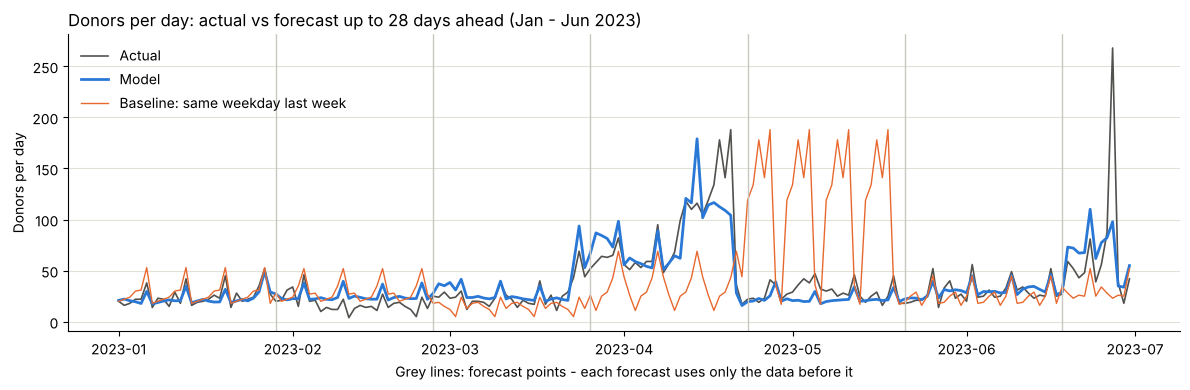

Test days: 181 in 7 blocks | model error 62% lower than the 28-day mean


,Model,Mean_last_28,Same_weekday_last_week,Days
All test days,9.8,25.6,30.8,181
Season days,20.0,52.4,49.8,44
Ordinary days,6.5,16.9,24.7,137


In [12]:
# FORECAST - Predict donors per day up to 28 days ahead, using only the calendar and the usual level a month earlier
#   Tested on Jan-Jun 2023 in 28-day blocks; every forecast uses only data before its block (no peeking).
#   Compared with two simple baselines: the mean of the last 28 days, and the same weekday last week.
assert "salary_27_window" in df_daily.columns and "s_ramadan_last10" in df_daily.columns, "Run STEP 6 and the seasons analysis first"

TEST_START, TEST_END, HORIZON = pd.Timestamp("2023-01-01"), df_daily["Gregorian_Date"].max(), 28
fc = df_daily.set_index("Gregorian_Date").copy()
ordinary = fc["Donors"].where(fc["any_season"] == 0)
# Usual level = mean donors on ordinary (non-season) days in the 56 days that end 28 days before the date:
# known at least 28 days in advance, so it can be used for any day in a 28-day forecast block.
fc["level"] = ordinary.shift(HORIZON).rolling(56, min_periods=14).mean()
FC_TERMS = "C(Weekday, Treatment('Sunday')) + " + " + ".join(list(SEASONS) + [c for c in fc.columns if c.endswith("_window")])

blocks, preds = pd.date_range(TEST_START, TEST_END, freq=f"{HORIZON}D"), []
for origin in blocks:
    train = fc[(fc.index < origin) & fc["has_data"] & fc["level"].notna()].reset_index()
    test = fc[(fc.index >= origin) & (fc.index < origin + pd.Timedelta(days=HORIZON)) & (fc.index <= TEST_END)].reset_index()
    m = smf.glm(f"Donors ~ {FC_TERMS}", train, family=sm.families.Poisson(), offset=np.log(train["level"])).fit()
    past = fc[(fc.index < origin) & fc["has_data"]]
    last_week = past["Donors"].iloc[-7:]
    test["Model"] = m.predict(test, offset=np.log(test["level"]))
    test["Mean_last_28"] = past["Donors"].iloc[-28:].mean()
    test["Same_weekday_last_week"] = test["Weekday"].map(dict(zip(past.loc[last_week.index, "Weekday"], last_week)))
    test["Origin"] = origin
    preds.append(test)
forecast = pd.concat(preds, ignore_index=True)
forecast = forecast[forecast["has_data"]].copy()

METHODS = ["Model", "Mean_last_28", "Same_weekday_last_week"]
def mae(g):
    return pd.Series({k: (g[k] - g["Donors"]).abs().mean() for k in METHODS} | {"Days": len(g)})
forecast_errors = pd.concat({
    "All test days": mae(forecast),
    "Season days": mae(forecast[forecast["any_season"] == 1]),
    "Ordinary days": mae(forecast[forecast["any_season"] == 0]),
}, axis=1).T.round(1)
forecast_errors["Days"] = forecast_errors["Days"].astype(int)
improvement = 1 - forecast_errors.loc["All test days", "Model"] / forecast_errors.loc["All test days", "Mean_last_28"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(forecast["Gregorian_Date"], forecast["Donors"], color="#52514e", linewidth=1.2, label="Actual")
ax.plot(forecast["Gregorian_Date"], forecast["Model"], color="#2a78d6", linewidth=2, label="Model")
ax.plot(forecast["Gregorian_Date"], forecast["Same_weekday_last_week"], color="#e8692f", linewidth=1, label="Baseline: same weekday last week")
for o in blocks[1:]:
    ax.axvline(o, color="#c9c7bf", linewidth=1)
ax.set_title(f"Donors per day: actual vs forecast up to {HORIZON} days ahead (Jan - Jun 2023)", loc="left")
ax.set_ylabel("Donors per day")
ax.set_xlabel("Grey lines: forecast points - each forecast uses only the data before it")
ax.grid(axis="y", color="#e1e0d9")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "forecast_2023.png", dpi=150)
plt.show()

assert forecast["Gregorian_Date"].min() >= TEST_START and forecast["Model"].notna().all()
print(f"Test days: {len(forecast)} in {len(blocks)} blocks | model error {improvement:.0%} lower than the 28-day mean")
display(forecast_errors)


## ساعة اليوم (تحليل وصفي)
متى في اليوم يتبرع الناس؟ الأوقات كما سُجلت في المصدر، والمنطقة الزمنية غير مذكورة (نمط السحور والإفطار في رمضان يرجّح توقيت السعودية).

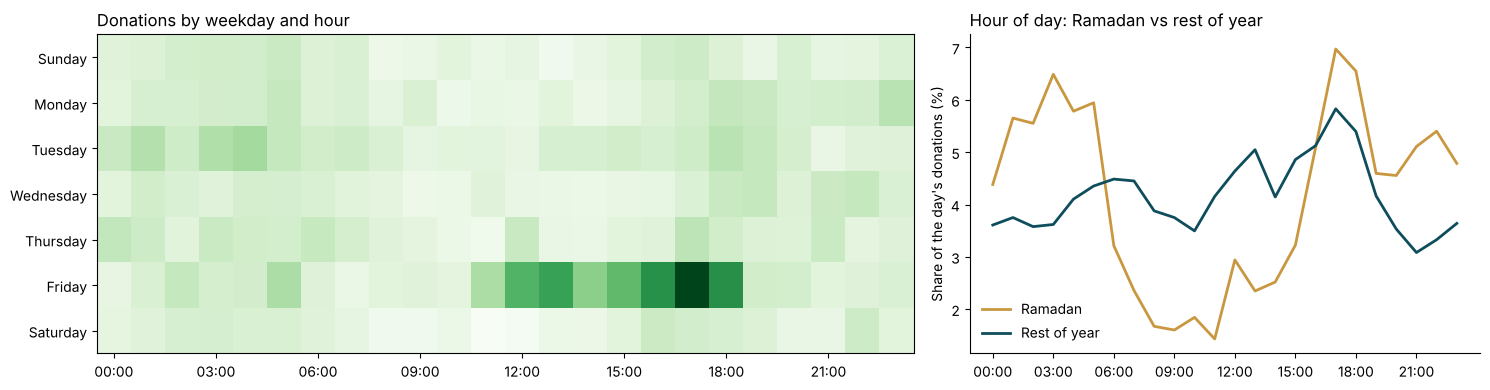

Busiest hour overall: 17:00 (6.2% of donations)


,Weekday,Hour,Donations
0,Friday,17,676
1,Friday,18,511
2,Friday,16,506
3,Friday,13,468
4,Friday,12,421


In [13]:
# HOURS (descriptive) - When in the day do donors give? Same donations as the analysis (no auto-charges, no duplicates)
#   Times as recorded in the source; the time zone is not stated (the Ramadan suhoor/iftar pattern suggests Saudi time).
times = raw.set_index("RowID").loc[df_analysis["RowID"], ["CreationTime"]].reset_index()
times["CreationTime"] = pd.to_datetime(times["CreationTime"])
times = times.merge(df_analysis[["RowID", "Hijri_Month"]], on="RowID")
times["Hour"] = times["CreationTime"].dt.hour
times["Weekday"] = times["CreationTime"].dt.day_name()
WEEK_ORDER = ["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]

heat = times.pivot_table(index="Weekday", columns="Hour", values="RowID", aggfunc="size", fill_value=0).reindex(WEEK_ORDER)
top_slots = (heat.stack().rename("Donations").sort_values(ascending=False).head(5).reset_index())
hour_share = pd.DataFrame({
    "Ramadan": times[times["Hijri_Month"] == 9]["Hour"].value_counts(normalize=True),
    "Rest of year": times[times["Hijri_Month"] != 9]["Hour"].value_counts(normalize=True),
}).reindex(range(24), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].imshow(heat.values, aspect="auto", cmap="Greens")
axes[0].set_yticks(range(7), WEEK_ORDER)
axes[0].set_xticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
axes[0].set_title("Donations by weekday and hour", loc="left")
axes[1].plot(hour_share.index, hour_share["Ramadan"] * 100, color="#c9973f", linewidth=2, label="Ramadan")
axes[1].plot(hour_share.index, hour_share["Rest of year"] * 100, color="#0e4d5c", linewidth=2, label="Rest of year")
axes[1].set_xticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
axes[1].set_ylabel("Share of the day's donations (%)")
axes[1].set_title("Hour of day: Ramadan vs rest of year", loc="left")
axes[1].legend(frameon=False)
for side in ["top", "right"]:
    axes[1].spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "analysis_hours.png", dpi=150)
plt.show()

assert heat.values.sum() == len(df_analysis)
print(f"Busiest hour overall: {times['Hour'].value_counts().idxmax():02d}:00 "
      f"({times['Hour'].value_counts(normalize=True).max():.1%} of donations)")
display(top_slots)


## حفظ المخرجات
كل الجداول إلى `outputs/tables/` بدون معرفات المتبرعين. في Colab يُنزَّل ملف `outputs.zip`.

In [14]:
# SAVE - Write every result table to outputs/tables (figures are already in outputs/figures)
TABLE_DIR = OUT_DIR / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
tables = {
    "candidate_periods": candidates, "not_supported": not_supported,
    "payday_results": payday_results, "season_results": season_results, "weekday_results": weekday_results,
    "payday_calendar": payday_calendar, "robustness": robustness, "robustness_summary": robustness_summary,
    "forecast_errors": forecast_errors.reset_index(names="Days_group"), "forecast_daily": forecast[["Gregorian_Date", "Donors"] + METHODS],
    "hours_weekday_heat": heat.reset_index(), "hours_top_slots": top_slots,
    "excluded_recurring": excluded_recurring.drop(columns="UserID_clean"), "excluded_duplicates": excluded_duplicates.drop(columns="UserID_clean"),
}
for name, t in tables.items():
    t.to_csv(TABLE_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

print(f"Saved {len(tables)} tables to {TABLE_DIR}/ and figures to {FIG_DIR}/ (no donor IDs in any saved file)")
if IN_COLAB:
    import shutil
    from google.colab import files as colab_files
    shutil.make_archive("outputs", "zip", OUT_DIR)
    colab_files.download("outputs.zip")


Saved 14 tables to outputs/tables/ and figures to outputs/figures/ (no donor IDs in any saved file)
